# Using False Colour Imagery to Depict Burn Scares from the 2025 Palisades and Eaton Fires in Los Angeles County, California
**Author: [Roshan Andres Nair](https://github.com/roshananair)**

**[GitHub Repository](https://github.com/roshananair/eds220-hwk4)**

## About
**Purpose:** 

_This notebook contains homework 4 for EDS 220: Working with Environmental Datasets. This code produces true and false colour images overlayed with perimeters of the Eaton and Palisades fires that occured in Los Angeles County, California in January of 2025. These maps are itended to demonstrate the application of false colour imagery in portraying landcover types, particularily in burned areas after a fire._

**Highlights:**

_The most important aspects of this exercise include: 1) Searching for and finding appropriate geospatial data from open data portals. 2) Finding information about geospatial datasets form the metadata and working with them to understand what information they contain, their CRS, etc. 3) Combining raster and vector (polygon) datasets. 4) Plotting different types of data with matplotlib. 5) Understanding how using different bands and false colour imagery can illuminate patterns that are not visible with true colour images._

**Data Description:**

_Data for these maps comes from two places: 1) Fire perimeter data is sourced from the California Department of Forestry and Fire Protection (CALFIRE) Fire and Resource Assessment Program (FRAP), which maintains and distributes this historical fire perimeter dataset for California. The specific subset of the data used in this instance is the Recent Large Fire Perimeters (GT 5000 acres), which contains information about and geometries for wildfires from 2021-2025 of 5000 acres or larger. Data was downloaded from the CALFIRE Open Data Portal hosted by ESRI's ArcGIS. 2) Landsat data was retrieved from the Microsoft Planetary Computer data catalogue and then clipped to an area surrounding the Los Angeles fires. This landsat dataset is Landsat Collection 2 Level-2, which contains atmospherically corrected surface reflectance and surfance temperature image data collected by the Landsat 8 satellite, of which a simplified collection of red, green, blue, SWIR, and NIR bands are used._

**References:**

1. California Department of Forestry and Fire Protection (CAL FIRE), Fire and Resource Assessment Program (FRAP). (2026). Recent Large Fire Perimeters (GT 5000 acres) [Sublayer 1], in California Historical Fire Perimeters (Version Firep25_1) [Data set]. ArcGIS Online. https://www.arcgis.com/home/item.html?id=c3c10388e3b24cec8a954ba10458039d&sublayer=1

2. Earth Resources Observation and Science (EROS) Center. (2020). Landsat 8-9 Operational Land Imager / Thermal Infrared Sensor Level-2, Collection 2 [Data set]. U.S. Geological Survey. https://doi.org/10.5066/P9OGBGM6

In [1]:
# Import packages
import pandas as pd
import xarray as xr
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

## 2. Fire perimeter data exploration

In [2]:
# URL for fire perimeters
service_url = 'https://services1.arcgis.com/jUJYIo9tSA7EHvfZ/arcgis/rest/services/California_Historic_Fire_Perimeters/FeatureServer/1/query?where=1%3D1&outFields=*&f=geojson'

In [3]:
# Reading in fire perimeters file from URL
fire_perimeters = gpd.read_file(service_url)

In [4]:
# Looking at info about the fire perimeters geodataframe
print(f"{fire_perimeters.info()}\nCRS: {fire_perimeters.crs}\nProjected? {fire_perimeters.crs.is_projected}\nGeographic? {fire_perimeters.crs.is_geographic}\nStates: {fire_perimeters['STATE'].unique()}\nFrom: {fire_perimeters['YEAR_'].min()}\nTo: {fire_perimeters['YEAR_'].max()}")

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 83 entries, 0 to 82
Data columns (total 23 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   OBJECTID       83 non-null     int64   
 1   YEAR_          83 non-null     int64   
 2   STATE          83 non-null     object  
 3   AGENCY         83 non-null     object  
 4   UNIT_ID        83 non-null     object  
 5   FIRE_NAME      83 non-null     object  
 6   INC_NUM        83 non-null     object  
 7   ALARM_DATE     83 non-null     int64   
 8   CONT_DATE      83 non-null     int64   
 9   CAUSE          83 non-null     int64   
 10  C_METHOD       83 non-null     int64   
 11  OBJECTIVE      82 non-null     float64 
 12  GIS_ACRES      83 non-null     float64 
 13  COMMENTS       20 non-null     object  
 14  COMPLEX_NAME   14 non-null     object  
 15  IRWINID        83 non-null     object  
 16  FIRE_NUM       0 non-null      object  
 17  COMPLEX_ID     14 non-null   

_The **fire_perimeters** GeoDataFrame has 22 columns and 83 rows of data, each corresponding to a "large" fire that burned, at least in part (One crosses border into Nevada), in California from 2021 to 2025. The GDF has a geographic CRS of EPSG:4326, and is unprojected._

## 3. NetCDF data import and exploration

In [5]:
# Reading in Palisades and Eaton fire landsat
fire_landsat = xr.open_dataset('data/landsat8-2025-02-23-palisades-eaton.nc')

In [6]:
# Looking at landsat dataset details
print(fire_landsat.info())

xarray.Dataset {
dimensions:
	y = 1418 ;
	x = 2742 ;

variables:
	float64 y(y) ;
		y:units = metre ;
		y:resolution = -30.0 ;
		y:crs = EPSG:32611 ;
		y:axis = Y ;
		y:long_name = y coordinate of projection ;
		y:standard_name = projection_y_coordinate ;
	float64 x(x) ;
		x:units = metre ;
		x:resolution = 30.0 ;
		x:crs = EPSG:32611 ;
		x:axis = X ;
		x:long_name = x coordinate of projection ;
		x:standard_name = projection_x_coordinate ;
	datetime64[ns] time() ;
	float32 red(y, x) ;
		red:grid_mapping = spatial_ref ;
	float32 green(y, x) ;
		green:grid_mapping = spatial_ref ;
	float32 blue(y, x) ;
		blue:grid_mapping = spatial_ref ;
	float32 nir08(y, x) ;
		nir08:grid_mapping = spatial_ref ;
	float32 swir22(y, x) ;
		swir22:grid_mapping = spatial_ref ;
	int64 spatial_ref() ;
		spatial_ref:crs_wkt = PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["

_The **fire_landsat** xarray.DataArray has an x dimension of 2742 meters and a y dimension of 1418 meters. Time is included as a coordinate variable, as well as spatial_ref which stores CRS metadata (EPSG:32611). Layers are rasters for red, green, blue, nir08, and swir22 bands._

## 4. Restoring geospatial information

In [7]:
# Checking CRS of the landsat dataset
print('CRS: ', fire_landsat.rio.crs)

CRS:  None


In [ ]:
# Looking at CRS metadata of the fire landsat dataset
print(fire_landsat['spatial_ref'].attrs['crs_wkt'])

PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]
CRS:  None


In [9]:
# Writing in a CRS for the 
fire_landsat = fire_landsat.rio.write_crs("EPSG:32611", inplace=False)
print('CRS: ', fire_landsat.rio.crs)

CRS:  EPSG:32611


## 5. True color image

C:\Users\rosha\.conda\envs\eds220-env\Lib\site-packages\matplotlib\cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


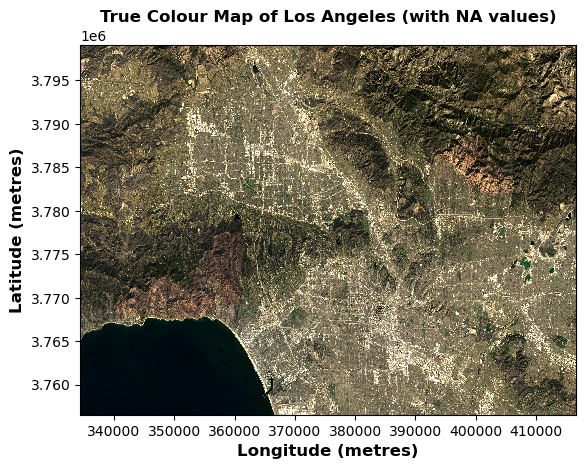

In [21]:
# Plotting red, green, and blue bands for a true colour landsat map
fig, ax = plt.subplots()

# Plotting true colour map of Los Angeles
fire_landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow(robust = True)

# Setting plot title
ax.set_title('True Colour Map of Los Angeles (with NA values)', fontsize = 12, fontweight = 'bold', color = 'black')

# Setting axis labels
ax.set_ylabel('Latitude (metres)', fontsize = 12, fontweight = 'bold', color = 'black')
ax.set_xlabel('Longitude (metres)', fontsize = 12, fontweight = 'bold', color = 'black')

plt.show()

In [82]:
# Checking for NA values in the red, green, and blue bands
print(np.isnan(fire_landsat[['red', 'green', 'blue']]).any())

<xarray.Dataset> Size: 15B
Dimensions:      ()
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int32 4B 0
Data variables:
    red          bool 1B False
    green        bool 1B True
    blue         bool 1B True


In [ ]:
# Filling Na values in the green and blue bands with zeros
fire_landsat[['green', 'blue']] = fire_landsat[['green', 'blue']].fillna(0)

# Checking if NA values were filled with zeros
print(np.isnan(fire_landsat[['red', 'green', 'blue']]).any())

<xarray.Dataset> Size: 15B
Dimensions:      ()
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int32 4B 0
Data variables:
    red          bool 1B False
    green        bool 1B False
    blue         bool 1B False


C:\Users\rosha\.conda\envs\eds220-env\Lib\site-packages\matplotlib\cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


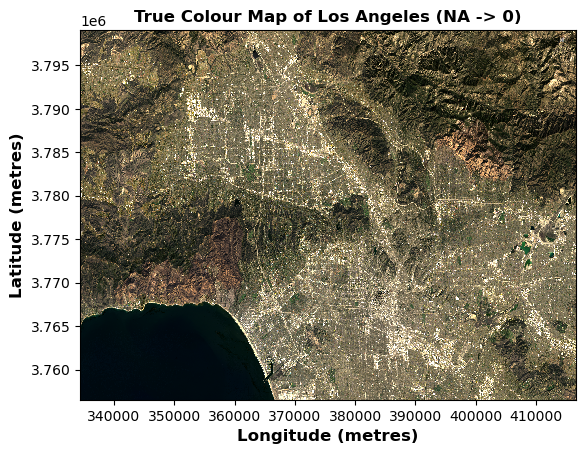

In [20]:
# Plotting red, green, and blue bands for a true colour landsat map with NA values replaced with zeros
fig, ax = plt.subplots()

# Plotting true colour map of Los Angeles
fire_landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow(robust = True)

# Setting plot title
ax.set_title('True Colour Map of Los Angeles (NA -> 0)', fontsize = 12, fontweight = 'bold', color = 'black')

# Setting axis labels
ax.set_ylabel('Latitude (metres)', fontsize = 12, fontweight = 'bold', color = 'black')
ax.set_xlabel('Longitude (metres)', fontsize = 12, fontweight = 'bold', color = 'black')

plt.show()

_The output in part a (the first map) contains NA values in the blue and green bands, which results a warning when plotting **(RuntimeWarning: invalid value encountered in cast xx = (xx * 255).astype(np.uint8))**. After setting the NA values in the blue and green bands to 0, the values are no longer 'invalid' and the warning subsides for the plotting in part e (the second map)._

## 6. False color image

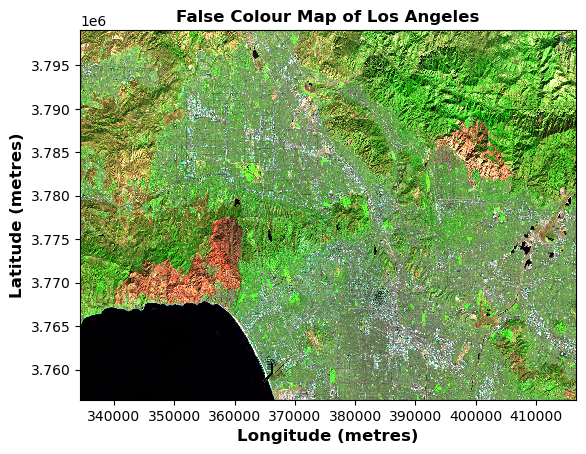

In [22]:
# Plotting SWIR, NIR, and red bands for a false colour landsat map
fig, ax = plt.subplots()

# Plotting true colour map of Los Angeles
fire_landsat[['swir22', 'nir08', 'red']].to_dataarray().plot.imshow(robust = True)

# Setting plot title
ax.set_title('False Colour Map of Los Angeles', fontsize = 12, fontweight = 'bold', color = 'black')

# Setting axis labels
ax.set_ylabel('Latitude (metres)', fontsize = 12, fontweight = 'bold', color = 'black')
ax.set_xlabel('Longitude (metres)', fontsize = 12, fontweight = 'bold', color = 'black')

plt.show()

## 7. Map

In [11]:
# Selecting geometries of fire perimeters for Eaton and Palisades fires
la_fires = fire_perimeters.loc[(fire_perimeters['FIRE_NAME'].isin(['EATON', 'PALISADES'])), 'geometry']

In [ ]:
# Checking CRS of fire perimeter geometries
print('CRS: ', la_fires.crs)

CRS:  EPSG:4326


In [ ]:
# Reprojecting fire perimeters from EPSG:4326 (degrees) to EPSG:32611 (meters)
la_fires = la_fires.to_crs("EPSG:32611")

# Checking reprojection
print('CRS: ', la_fires.crs)

CRS:  EPSG:32611


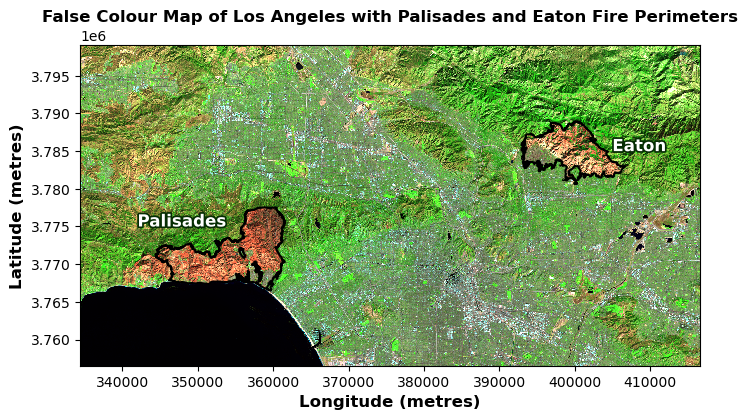

In [ ]:
# Plotting false colour map of Los Angeles with Eaton and Palisades fire perimeters
fig, ax = plt.subplots(figsize = (8, 8))

# Plotting false colour landsat
fire_landsat[['swir22', 'nir08', 'red']].to_dataarray().plot.imshow(robust = True, ax = ax)

# Plotting fire perimeters
la_fires.plot(ax = ax, facecolor = 'none', edgecolor = 'black', linewidth = 1.5)

# Setting plot title
ax.set_title('False Colour Map of Los Angeles with Palisades and Eaton Fire Perimeters', fontsize = 12, fontweight = 'bold', color = 'black')

# Setting text outline for fire labels
outline = [pe.withStroke(linewidth =2.5, foreground = '#062D03')]

# Setting fire perimeter labels
ax.text(342000, 3775000, 'Palisades', fontweight = 'bold', fontsize = 12, color = 'white', path_effects = outline)
ax.text(405000, 3785000, 'Eaton', fontweight = 'bold', fontsize = 12, color = 'white', path_effects = outline)

# Setting axis labels
ax.set_ylabel('Latitude (metres)', fontsize = 12, fontweight = 'bold', color = 'black')
ax.set_xlabel('Longitude (metres)', fontsize = 12, fontweight = 'bold', color = 'black')

plt.show()


_The Palisades and Eaton fires in Los Angeles, California both burned in January of 2025. This map depicts the outlines of the two fire perimeters overlayed on a false colour map, which brings out the contrast of burned areas (red) compared to vegetation and urban areas (green/blue, other colours). The false color image, where landsat bands are ordered 6, 5, 4 (corresponding to shortwave infrared 1, near infrared, and red, respectively) is a common band combination used for vegetative analysis to pick up differences in vegetation cover. In this case, you can see the burn scars of these two large fires clearly on the backdrop of unburned vegetation and urban area. It is also clear that to the West of the Palisades fire there is an additonal red area, which corresponds to the burn scar left by the Franklin fire, which occured less than a moth prior to the Palisades and Eaton fires in December of 2024._